# 02 - Análisis exploratorio (EDA)

Se trabaja **solo con el conjunto etiquetado** (`smoking_prediction.xlsx`).

Preguntas guía:
1. ¿Cómo se distribuye cada variable y hay valores extremos?
2. ¿Qué variables separan fumadores de no fumadores?
3. ¿Ese efecto se mantiene **dentro de cada género** o es solo el efecto del sexo?
4. ¿Hay variables redundantes entre sí?
5. ¿Qué decisiones se toman para el preprocesamiento (03)?

#### Dependencias

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

#### Parametros

In [2]:
FILE_TRAIN = Path("../data/raw/smoking_prediction.xlsx")
TARGET = "smoking"
ID_COL = "ID"
DESCARTAR = [ID_COL, "oral"]  # identificador y constante (ver notebook 01)

sns.set_theme(style="whitegrid")
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", None)

#### Funciones

In [3]:
def tasa_por_grupo(df, col):
    """Tasa de fumadores (media del target) y cantidad de filas por valor de `col`."""
    return df.groupby(col, observed=True)[TARGET].agg(tasa="mean", n="size").round(3)

#### Lectura

In [4]:
df = pd.read_excel(FILE_TRAIN).drop(columns=DESCARTAR)

binarias = [c for c in df.columns if c != TARGET and df[c].nunique() == 2]
cat_cols = df.select_dtypes(include="object").columns.tolist()
num_cols = [c for c in df.select_dtypes(include="number").columns
            if c not in (TARGET, *binarias)]  # continuas / discretas con rango amplio

print("Forma:", df.shape)
print("Categoricas:", cat_cols)
print("Binarias numericas:", [c for c in binarias if c not in cat_cols])
print("Numericas:", len(num_cols))

Forma: (50000, 25)
Categoricas: ['gender', 'tartar']
Binarias numericas: ['hearing(left)', 'hearing(right)', 'dental caries']
Numericas: 19


## 1. Distribuciones

Histograma + KDE de cada numérica. Sirve para ver forma (simétrica o asimétrica), colas largas y valores discretos.

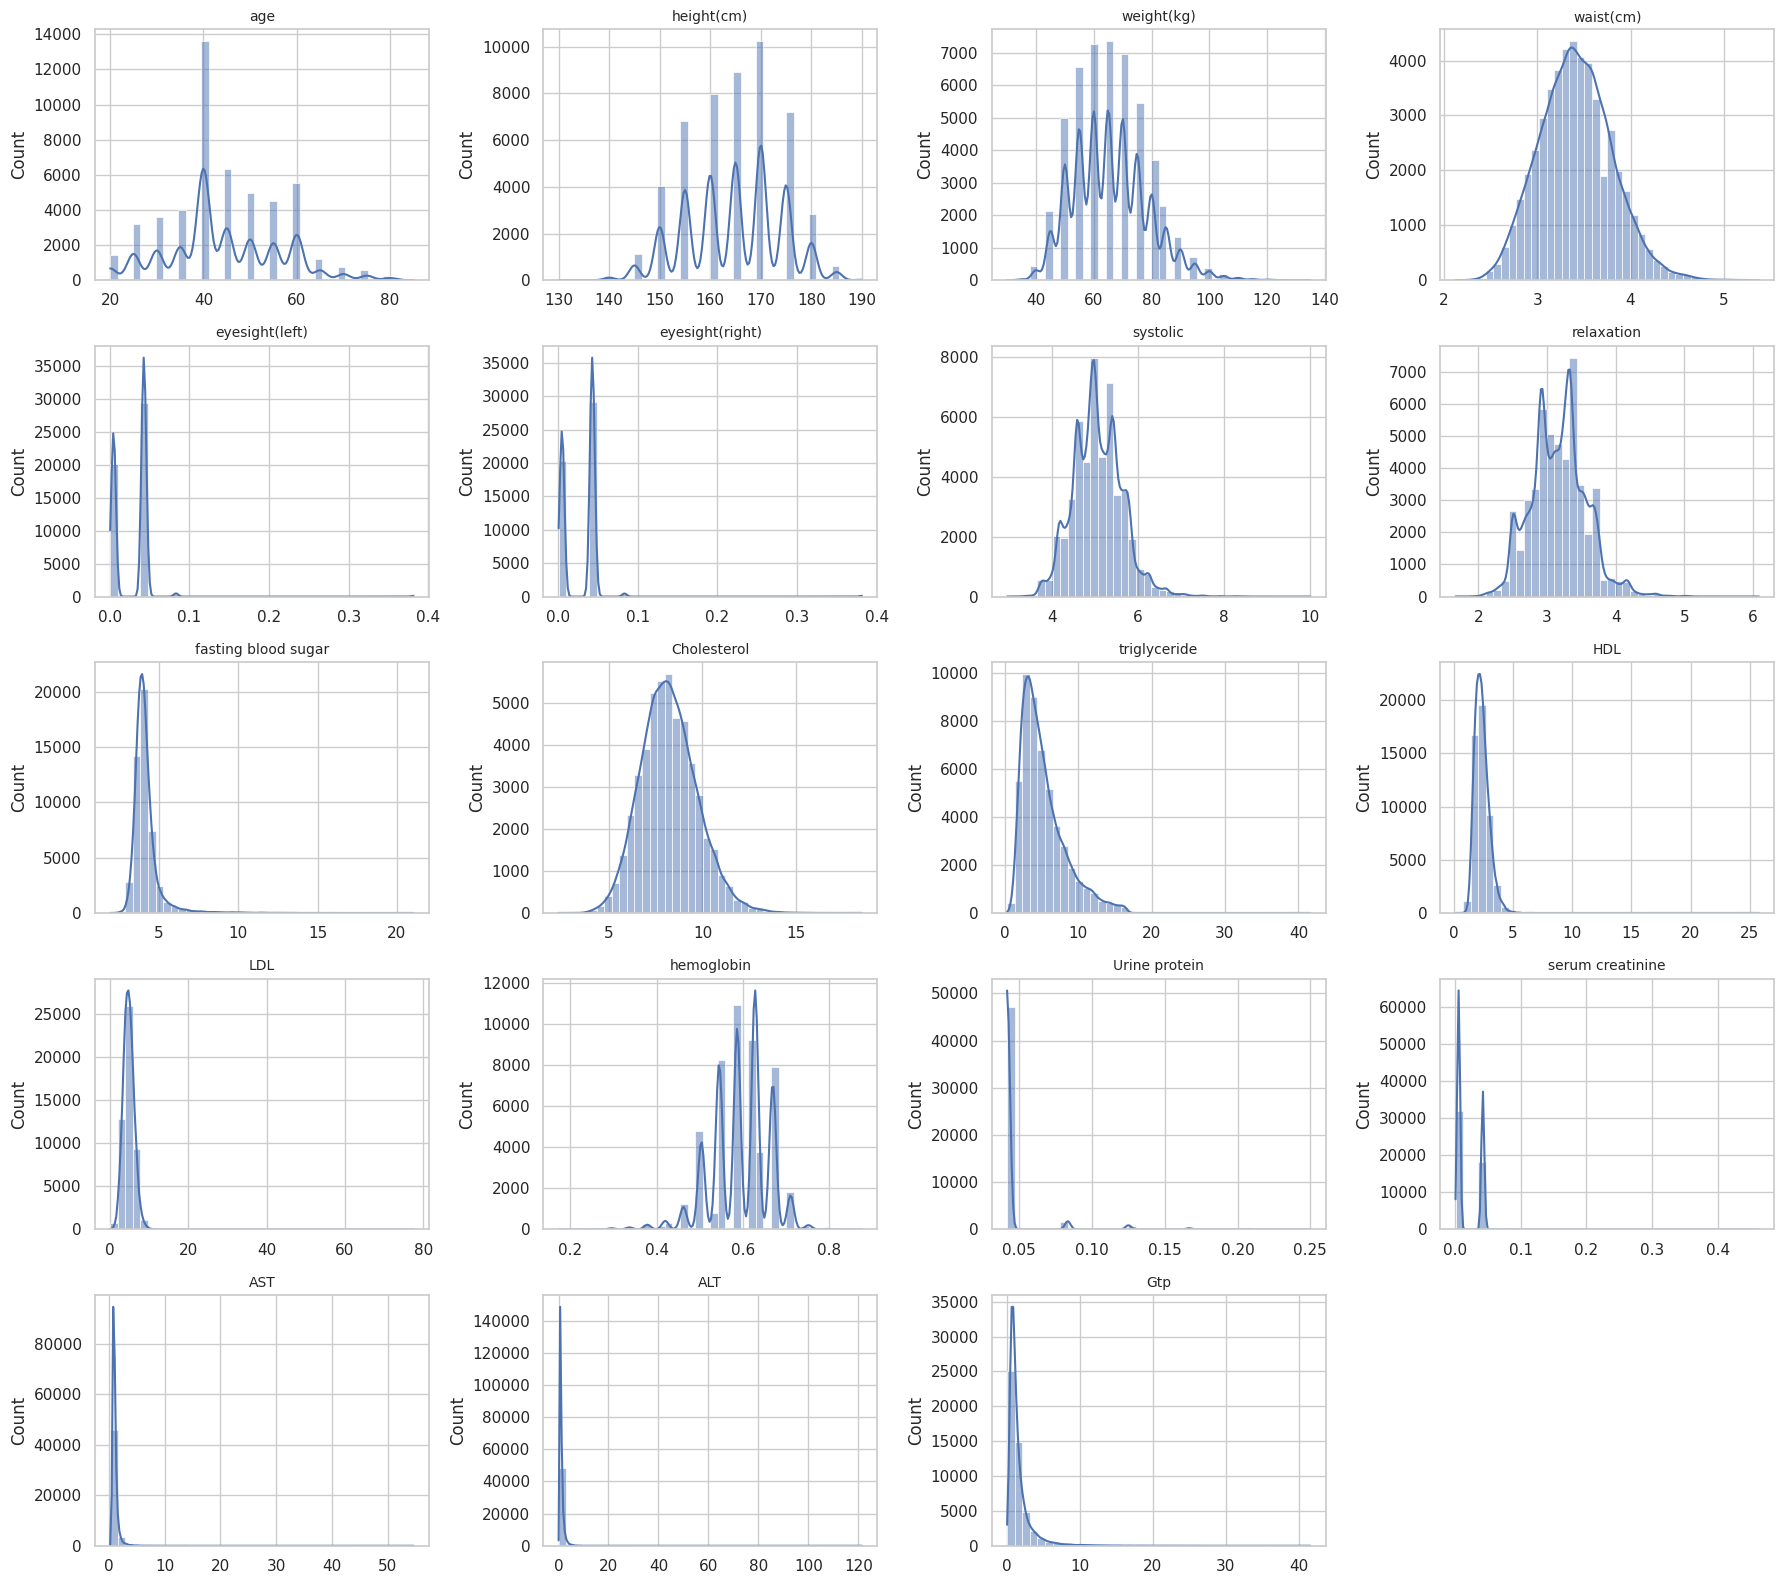

In [5]:
fig, axes = plt.subplots(5, 4, figsize=(18, 16))
for ax, c in zip(axes.ravel(), num_cols):
    sns.histplot(df[c], kde=True, bins=40, ax=ax)
    ax.set_title(c, fontsize=10); ax.set_xlabel("")
for ax in axes.ravel()[len(num_cols):]:
    ax.axis("off")
plt.tight_layout(); plt.show()

In [6]:
asim = df[num_cols].skew().sort_values(ascending=False).round(1)
asim.to_frame("asimetria").T

,ALT,AST,LDL,Gtp,Urine protein,eyesight(right),eyesight(left),fasting blood sugar,HDL,serum creatinine,triglyceride,weight(kg),systolic,relaxation,Cholesterol,age,waist(cm),height(cm),hemoglobin
asimetria,35.2,25.6,11.0,6.8,5.7,5.1,5.0,4.5,2.1,1.8,1.3,0.5,0.5,0.4,0.4,0.3,0.2,-0.1,-0.6


Las variables de laboratorio (`ALT`, `AST`, `LDL`, `Gtp`, `fasting blood sugar`) tienen **asimetría positiva fuerte**: muchos valores normales y una cola larga de valores muy altos. `eyesight`, `hearing` y `Urine protein` son casi discretas (pocos valores distintos). En cambio `age`, `height`, `weight`, `Cholesterol`, `systolic` y `relaxation` son aproximadamente simétricas.

## 2. Valores extremos

Se aplica la regla del IQR (1,5 × IQR) solo a las numéricas continuas. Para las binarias no aplica.

In [7]:
q1, q3 = df[num_cols].quantile(0.25), df[num_cols].quantile(0.75)
iqr = q3 - q1
fuera = ((df[num_cols] < q1 - 1.5 * iqr) | (df[num_cols] > q3 + 1.5 * iqr))
pd.DataFrame({"% fuera IQR": fuera.mean().mul(100).round(1), "min": df[num_cols].min().round(2),
              "max": df[num_cols].max().round(2)}).sort_values("% fuera IQR", ascending=False)

,% fuera IQR,min,max
Gtp,8.7,0.04,41.62
ALT,6.7,0.04,121.42
fasting blood sugar,6.0,1.92,21.04
Urine protein,5.5,0.04,0.25
AST,5.4,0.25,54.62
triglyceride,4.0,0.33,41.62
relaxation,2.1,1.67,6.08
HDL,1.8,0.17,25.75
systolic,1.2,2.96,10.00
hemoglobin,1.2,0.17,0.88


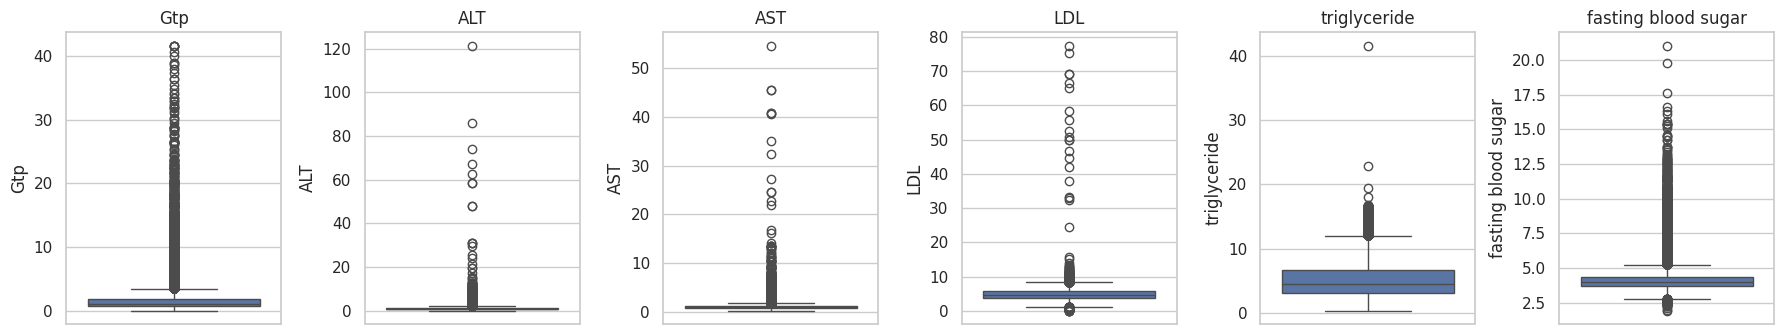

In [8]:
cols_box = ["Gtp", "ALT", "AST", "LDL", "triglyceride", "fasting blood sugar"]
fig, axes = plt.subplots(1, len(cols_box), figsize=(18, 3.5))
for ax, c in zip(axes, cols_box):
    sns.boxplot(y=df[c], ax=ax); ax.set_title(c)
plt.tight_layout(); plt.show()

Hasta 9% de las filas quedan fuera del IQR en `Gtp`, `ALT` y `AST`. En salud los valores altos suelen ser **casos reales** (enfermedad hepática, por ejemplo) y no errores de carga. Por eso **no se eliminan filas**. Además el archivo de entrega puede tener casos así, y hay que poder predecirlos. Se tratan en el 03 con una transformación (`log1p`) o usando modelos de árboles, que no se afectan.

## 3. Variables vs. target

### 3.1 Categóricas y binarias: tasa de fumadores

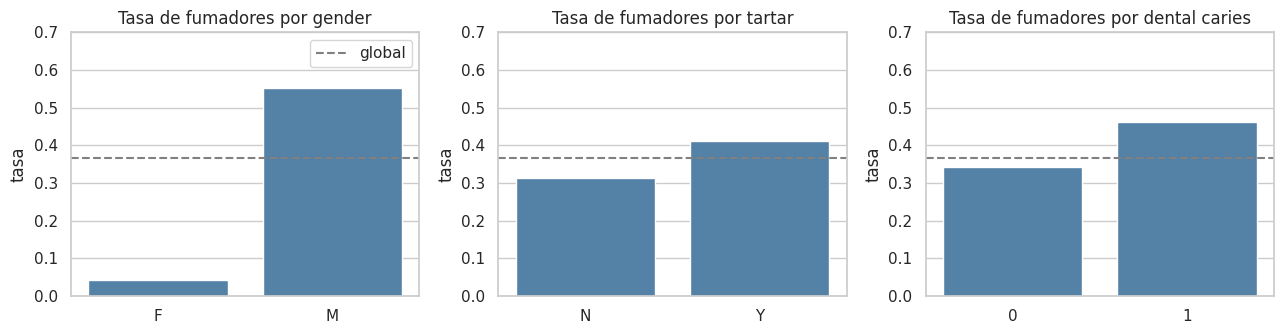

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.5))
for ax, c in zip(axes, ["gender", "tartar", "dental caries"]):
    t = tasa_por_grupo(df, c)
    sns.barplot(x=t.index.astype(str), y=t["tasa"], ax=ax, color="steelblue")
    ax.axhline(df[TARGET].mean(), color="gray", ls="--", label="global")
    ax.set_title(f"Tasa de fumadores por {c}"); ax.set_xlabel(""); ax.set_ylim(0, 0.7)
axes[0].legend(); plt.tight_layout(); plt.show()

- `gender` es el efecto dominante (55% en hombres vs 4% en mujeres).
- `tartar` y `dental caries` suben la tasa unos 10-12 puntos, pero hay que ver si se mantiene dentro de cada género.

### 3.2 Edad

In [10]:
df["grupo_edad"] = pd.cut(df["age"], [0, 30, 40, 50, 60, 90])
print(tasa_por_grupo(df, "grupo_edad"))
print()
print(df.pivot_table(index="grupo_edad", columns="gender", values=TARGET, aggfunc="mean", observed=True).round(3))

             tasa      n
grupo_edad              
(0, 30]     0.477   8258
(30, 40]    0.405  17628
(40, 50]    0.340  11297
(50, 60]    0.285  10039
(60, 90]    0.194   2778

gender          F      M
grupo_edad              
(0, 30]     0.167  0.478
(30, 40]    0.057  0.607
(40, 50]    0.041  0.637
(50, 60]    0.032  0.534
(60, 90]    0.016  0.316


En total la tasa **baja con la edad** (≈48% en menores de 30 contra ≈19% en mayores de 60), pero la tabla cruzada muestra que el patrón es distinto por género. En mujeres baja con la edad (17% → 2%). En hombres es **no lineal**: sube hasta los 40-50 años (64%) y recién después baja (32% en mayores de 60). Parte de la caída total se debe a la composición por sexo y edad, y el efecto de la edad depende del género. Es una **interacción edad × género** que un modelo de árboles puede capturar, y que una regresión logística simple no.

### 3.3 Numéricas: distribución por clase

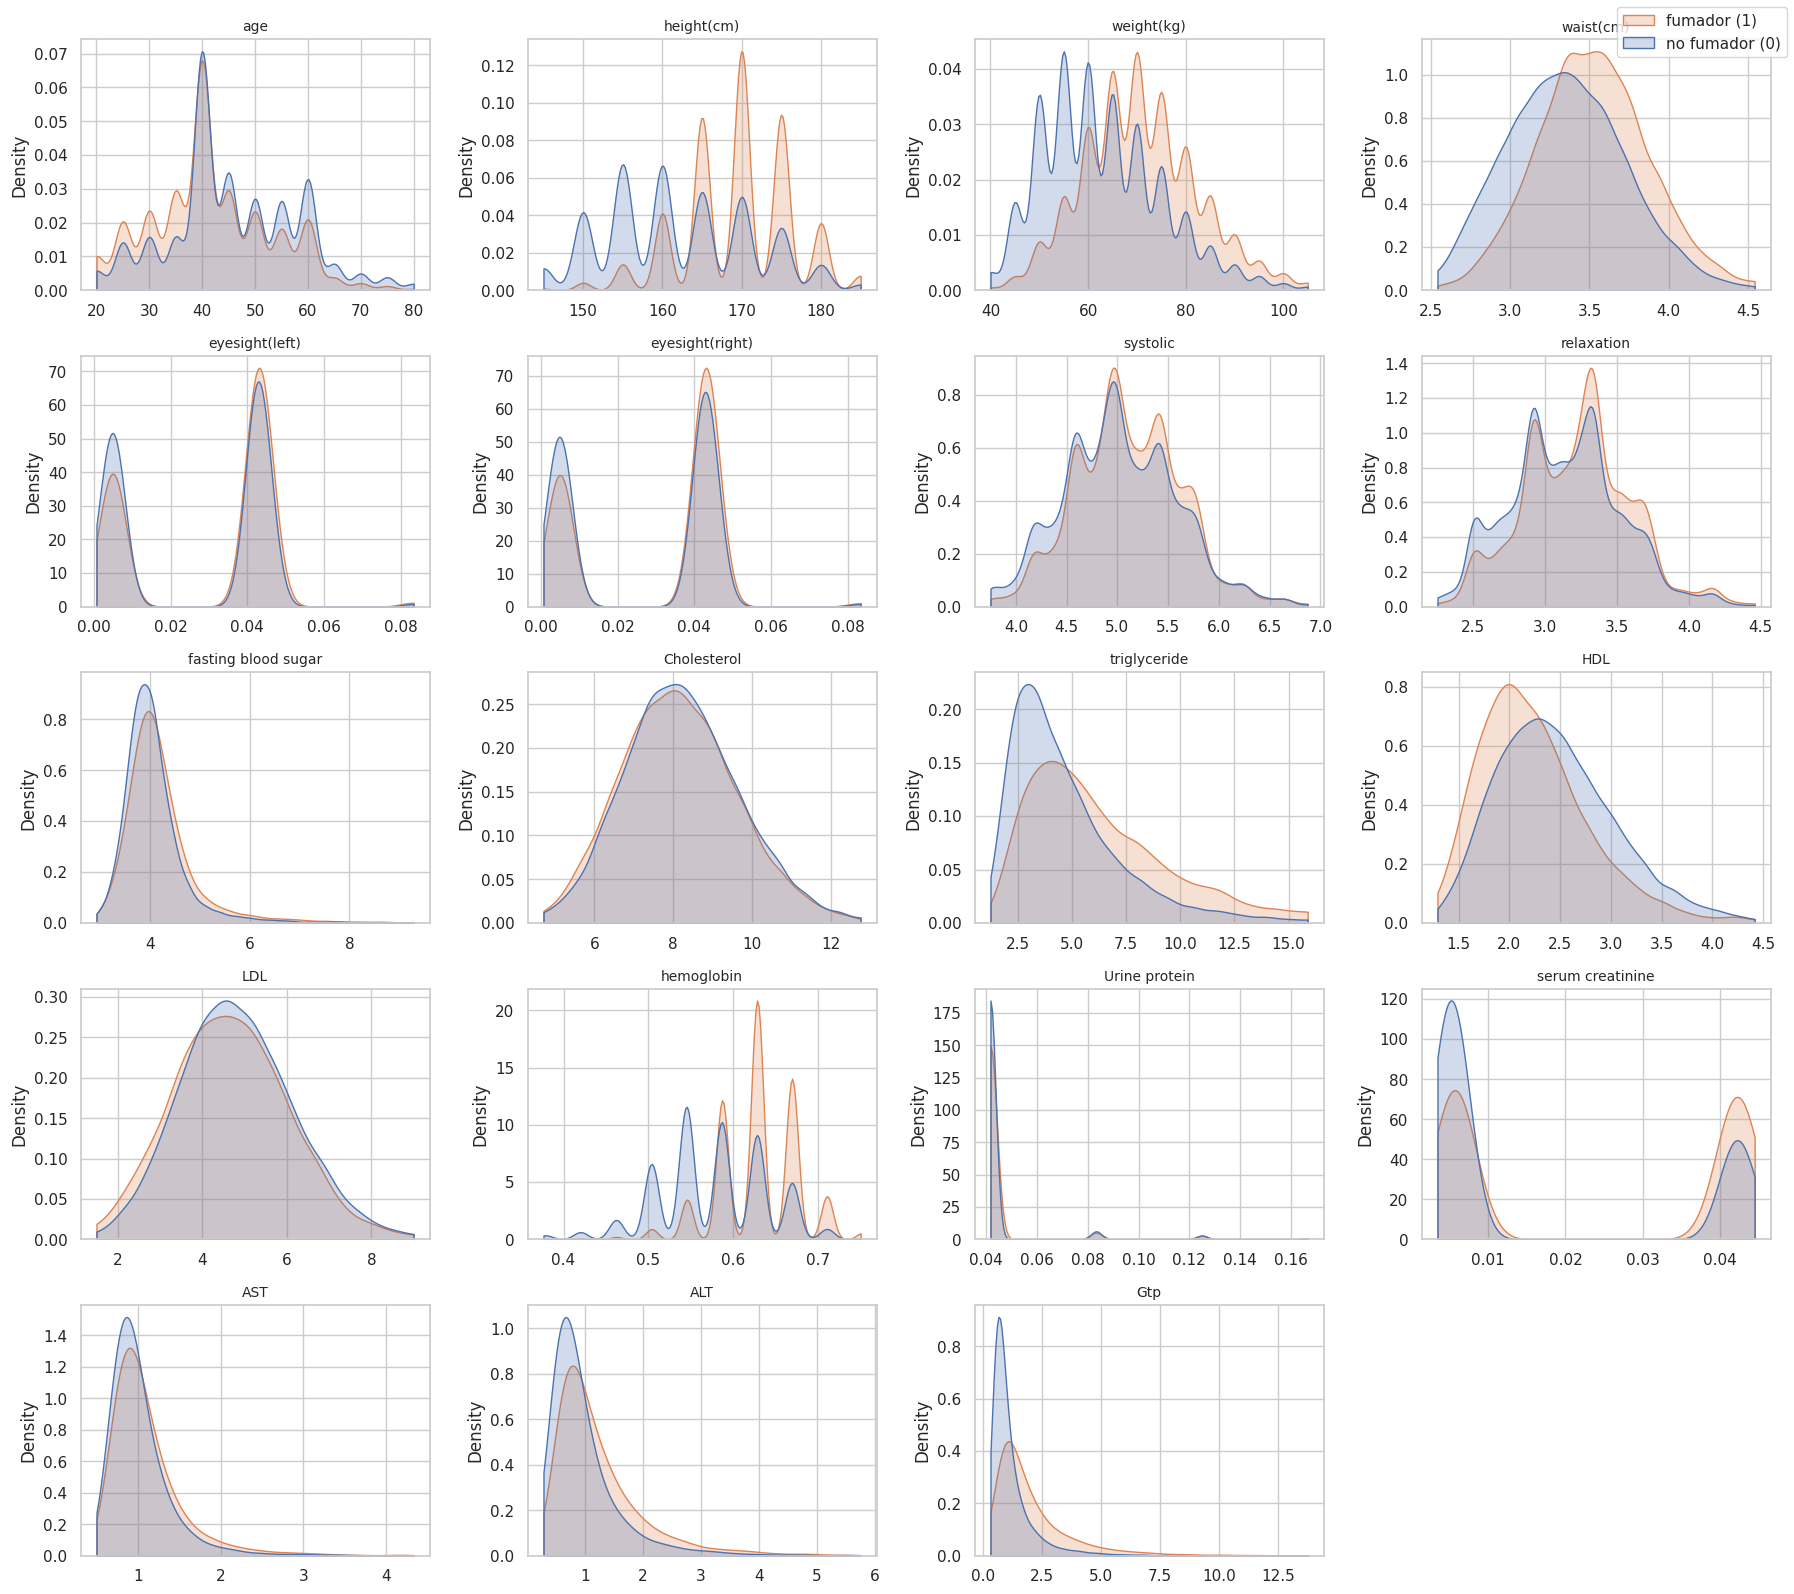

In [11]:
fig, axes = plt.subplots(5, 4, figsize=(18, 16))
for ax, c in zip(axes.ravel(), num_cols):
    sns.kdeplot(data=df, x=c, hue=TARGET, common_norm=False, fill=True, ax=ax, legend=False,
                clip=(df[c].quantile(0.005), df[c].quantile(0.995)))
    ax.set_title(c, fontsize=10); ax.set_xlabel("")
for ax in axes.ravel()[len(num_cols):]:
    ax.axis("off")
fig.legend(["fumador (1)", "no fumador (0)"], loc="upper right")
plt.tight_layout(); plt.show()

## 4. ¿Es efecto del género?

Se compara la correlación de cada numérica con el target **en total** y **dentro de cada género**. Si cae mucho, la variable era en buena parte un reflejo del sexo.

In [12]:
corr = pd.DataFrame({
    "total": df[num_cols + [TARGET]].corr()[TARGET],
    "hombres": df[df.gender == "M"][num_cols + [TARGET]].corr()[TARGET],
    "mujeres": df[df.gender == "F"][num_cols + [TARGET]].corr()[TARGET],
}).drop(TARGET).round(2)
corr = corr.sort_values("total", key=abs, ascending=False)
corr

,total,hombres,mujeres
height(cm),0.40,0.03,0.04
hemoglobin,0.40,0.08,0.05
weight(kg),0.30,0.01,0.01
triglyceride,0.25,0.17,0.07
Gtp,0.24,0.14,0.09
waist(cm),0.22,0.02,0.00
serum creatinine,0.20,-0.06,-0.00
HDL,-0.18,-0.04,0.01
age,-0.16,-0.01,-0.06
relaxation,0.11,0.03,-0.01


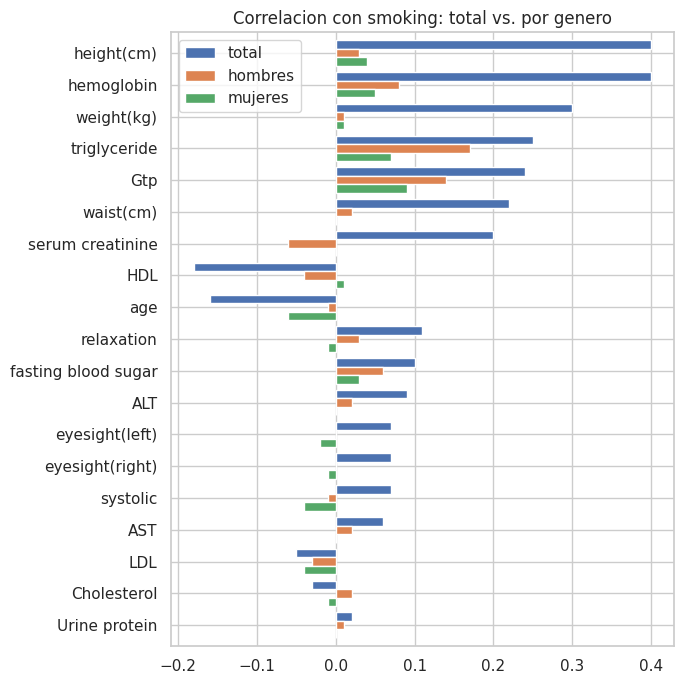

In [13]:
fig, ax = plt.subplots(figsize=(7, 7))
corr.plot.barh(ax=ax, width=0.8)
ax.invert_yaxis(); ax.set_title("Correlacion con smoking: total vs. por genero")
plt.tight_layout(); plt.show()

Este es el hallazgo central del EDA:
- `height(cm)` y `hemoglobin` (correlación ≈ 0,40 en total) **casi no se relacionan con fumar dentro de un mismo género** (≈ 0,05-0,08). Los hombres son más altos y tienen más hemoglobina y además fuman más. Son variables que, en gran parte, reemplazan al sexo.
- Las que más conservan señal dentro del género son `triglyceride` y `Gtp`, sobre todo en hombres (0,17 y 0,14). `age` tiene correlación lineal casi nula dentro de cada género (su efecto es no lineal, ver 3.2).
- Las señales individuales dentro de cada género son **débiles** (correlaciones lineales ≤ 0,17). El poder predictivo va a venir de combinar muchas variables y de las interacciones con `gender`, lo que favorece a los modelos de árboles y ensambles.

In [14]:
print(df.pivot_table(index="tartar", columns="gender", values=TARGET, aggfunc="mean").round(3))
print()
print(df.pivot_table(index="dental caries", columns="gender", values=TARGET, aggfunc="mean").round(3))

gender      F      M
tartar              
N       0.032  0.495
Y       0.052  0.594

gender             F      M
dental caries              
0              0.039  0.530
1              0.061  0.623


`tartar` y `dental caries` mantienen un efecto positivo dentro de cada género (por ejemplo en hombres, 49% sin sarro contra 59% con sarro), así que se conservan.

## 5. Relaciones entre variables

Matriz de correlación entre predictoras, para detectar redundancia.

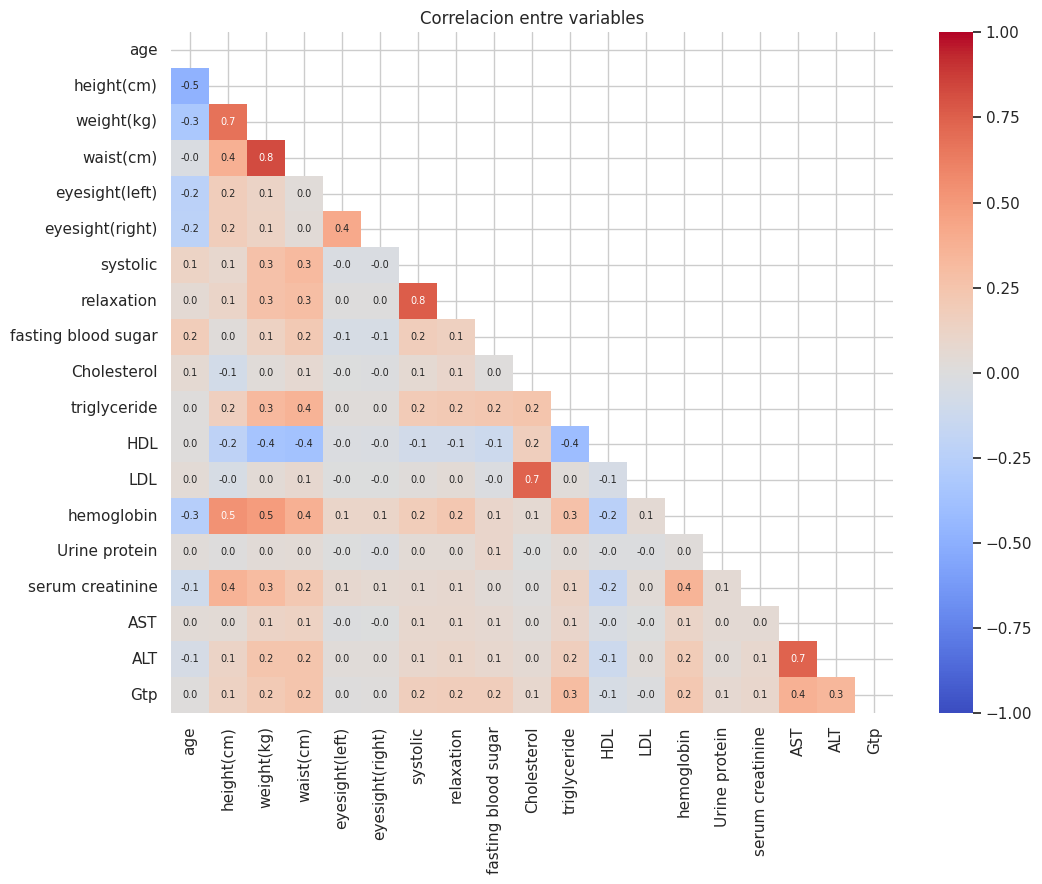

,,correlacion
weight(kg),waist(cm),0.82
systolic,relaxation,0.76
Cholesterol,LDL,0.74
AST,ALT,0.74
height(cm),weight(kg),0.68


In [15]:
c = df[num_cols].corr()
fig, ax = plt.subplots(figsize=(11, 9))
sns.heatmap(c, mask=np.triu(np.ones_like(c, dtype=bool)), cmap="coolwarm", center=0, vmin=-1, vmax=1,
            annot=True, fmt=".1f", annot_kws={"size": 7}, ax=ax)
ax.set_title("Correlacion entre variables"); plt.tight_layout(); plt.show()

pares = c.where(np.triu(np.ones(c.shape), 1).astype(bool)).stack()
pares[pares.abs() > 0.6].sort_values(ascending=False).round(2).to_frame("correlacion")

Hay pares correlacionados: `weight`-`waist` (0,82), `systolic`-`relaxation` (0,76), `Cholesterol`-`LDL` (0,74), `AST`-`ALT` (0,74) y `height`-`weight` (0,68). Ninguno supera 0,85, así que no hay redundancia total. Los árboles toleran esto sin problema. Para regresión logística habría que vigilar la multicolinealidad.

## 6. Ideas de variables nuevas (feature engineering)

Se prueban rápido combinaciones con sentido clínico, para ver si valen la pena en el 03.

In [16]:
fe = pd.DataFrame({
    "imc": df["weight(kg)"] / (df["height(cm)"] / 100) ** 2,
    "tension_diferencial": df["systolic"] - df["relaxation"],
    "col_total_hdl": df["Cholesterol"] / df["HDL"],
    "ldl_hdl": df["LDL"] / df["HDL"],
    "ast_alt": df["AST"] / df["ALT"],
    "cintura_altura": df["waist(cm)"] * 24 / df["height(cm)"],  # waist esta dividido por 24 (ver 01)
})
fe[TARGET] = df[TARGET]
res = pd.DataFrame({"total": fe.corr()[TARGET], "hombres": fe[df.gender == "M"].corr()[TARGET],
                    "mujeres": fe[df.gender == "F"].corr()[TARGET]}).drop(TARGET).round(3)
res

,total,hombres,mujeres
imc,0.105,-0.002,-0.013
tension_diferencial,-0.005,-0.047,-0.044
col_total_hdl,0.146,0.059,-0.014
ldl_hdl,0.071,0.009,-0.032
ast_alt,-0.173,-0.019,-0.003
cintura_altura,0.028,0.005,-0.008


Ninguna combinación muestra una señal lineal fuerte dentro de cada género (todas ≤ 0,06 en valor absoluto). `col_total_hdl` y `ast_alt` tienen correlación total mayor, pero casi desaparece al separar por género, o sea que también reflejan el sexo. La correlación lineal no descarta una relación no lineal, así que se prueban en el 03/04 y se quedan solo si mejoran el F1 en validación.

## 7. Conclusiones y decisiones para el preprocesamiento

| Hallazgo | Decisión (notebook 03) |
|---|---|
| `gender` explica gran parte de la señal (55% vs 4%) | Mantener; codificar a 0/1 |
| `height` y `hemoglobin` son sobre todo proxy del sexo | Mantener (los modelos las combinan con `gender`), pero no sobreinterpretar su importancia |
| Señal propia débil: `triglyceride`, `Gtp`, `tartar`, `dental caries`; `age` con efecto no lineal que depende del género | Mantener; probar interacciones con `gender` (árboles lo hacen solos) |
| Asimetría fuerte en `ALT`, `AST`, `LDL`, `Gtp`, glucosa | `log1p` si el modelo lo necesita (regresión, KNN); árboles no lo requieren |
| Valores extremos probablemente reales | **No eliminar filas** |
| Columnas con pocos valores (`eyesight`, `hearing`, `Urine protein`) | Tratar como numéricas discretas; evaluar su aporte |
| Correlaciones moderadas entre predictoras (máx. 0,82) | Sin eliminar variables; vigilar en modelos lineales |
| Escalas distintas | `StandardScaler` dentro del pipeline si el modelo lo requiere |
| Ideas de features: IMC, tensión diferencial, cocientes de colesterol y enzimas (señal lineal débil) | Probar de a una y quedarse solo con las que mejoren el F1 en validación |

**Modelos candidatos:** ensambles de árboles (Random Forest, XGBoost / gradient boosting), dado que las señales son débiles, no lineales y con interacciones. Una regresión logística sirve como línea base.